# LAB 04 — Text Classification
**Môn học:** Xử lý ngôn ngữ tự nhiên và ứng dụng — Học kỳ I, 2026  
**Sinh viên:** `Nguyễn Mạnh Dũng` — **MSSV:** `23001507`  
**Hạn nộp:** 23:59 — 14/10/2026

**Dataset được chọn:** IMDb (Sentiment, binary: negative / positive)  
**Application:** Option A — Sentiment classification

**Câu hỏi trọng tâm:** *Representation nào phù hợp với bài toán nào, tại sao, và model đang sai ở đâu?*

**Cấu trúc notebook** (tương ứng các deliverable `README.md`, `calculations.md`, `prediction.md`, `classification.ipynb`, `preprocessing.py`, `results.csv`, `confusion_matrix.png`, `error_analysis.md`, `reflection.md`):

0. Setup
1. Theory & Calculation (Bài 1–4)
2. Prediction (trước khi chạy experiment)
3. Experiment 1 — Dataset inspection + split + data leakage
4. Core implementation & Baseline (TF-IDF + LR)
5. Experiment 3 — Representation comparison (TF-IDF vs Avg Word2Vec vs Linear SVM)
6. Experiment 4 — Word order · Experiment 5 — n-gram
7. Kiểm chứng Prediction 3, 4, 5
8. Evaluation & Confusion matrix
9. Error analysis
10. Inspect model weights
11. Application
12. Reflection · Individual learning check · AI assistance statement

## 0. Setup

In [6]:
!pip install -q datasets scikit-learn gensim matplotlib seaborn pandas

In [7]:
import re, time, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from gensim.models import Word2Vec

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
LABELS = {0: "negative", 1: "positive"}

# Đặt SUBSAMPLE = 5000 (ví dụ) nếu muốn chạy nhanh để debug; None = dùng toàn bộ dữ liệu
SUBSAMPLE = None
sns.set_theme(style="whitegrid")

## 1. Theory & Calculation  *(→ `calculations.md`)*

### Bài 1 — Binary classification
$x=[1,2,0],\; w=[0.5,-0.2,0.4],\; b=0.1$

$$z = w^\top x + b = 0.5\cdot1 + (-0.2)\cdot2 + 0.4\cdot0 + 0.1 = 0.5 - 0.4 + 0 + 0.1 = 0.2$$

$$P(y=1\mid x)=\sigma(0.2)=\frac{1}{1+e^{-0.2}}=\frac{1}{1+0.8187}\approx \mathbf{0.5498}$$

### Bài 2 — Prediction threshold
$P(y=1\mid x)=0.72$

- $\tau = 0.5$: $0.72 \ge 0.5 \Rightarrow$ dự đoán **class 1 (positive)**.
- $\tau = 0.8$: $0.72 < 0.8 \Rightarrow$ dự đoán **class 0 (negative)**.

**Ảnh hưởng của threshold:**
- **Tăng** $\tau$ → model "khó tính" hơn khi gán positive → ít dự đoán positive → FP giảm, FN tăng ⇒ **precision thường tăng, recall giảm**.
- **Giảm** $\tau$ → model dễ gán positive → FP tăng, FN giảm ⇒ **precision thường giảm, recall tăng**.
- Hai metric này đánh đổi nhau; chọn $\tau$ tùy chi phí của từng loại lỗi (xem thêm đường Precision–Recall).

### Bài 3 — Confusion matrix

| | Pred Positive | Pred Negative |
|---|---|---|
| **Actual Positive** | TP = 80 | FN = 20 |
| **Actual Negative** | FP = 10 | TN = 90 |

$$\text{Precision}=\frac{TP}{TP+FP}=\frac{80}{90}\approx 0.8889,\quad
\text{Recall}=\frac{TP}{TP+FN}=\frac{80}{100}=0.8$$

$$F_1=\frac{2PR}{P+R}=\frac{2\cdot0.8889\cdot0.8}{0.8889+0.8}\approx \mathbf{0.8421},\qquad
\text{Accuracy}=\frac{80+90}{200}=0.85$$

**Nếu là bài toán phát hiện spam (positive = spam):**
- **False Positive** (FP = 10): email *bình thường* bị đánh nhầm là spam → người dùng **có thể mất email quan trọng** (lỗi thường tốn kém hơn).
- **False Negative** (FN = 20): email *spam* lọt vào inbox → gây phiền, có thể chứa lừa đảo/phishing.

### Bài 4 — Accuracy trap
950 negative / 50 positive; model luôn dự đoán negative: $TP=0,\;FN=50,\;FP=0,\;TN=950$.

- Accuracy $=950/1000=95\%$.
- Recall(positive) $=0/50=0$ → **bỏ sót toàn bộ** positive.
- Precision(positive) $=0/0$ → không xác định (quy ước 0).
- $F_1$(positive) $=0$; $F_1$(negative) $\approx0.974$ ⇒ **macro-F1 $\approx0.487$**.

**Kết luận:** model này **không** thực sự tốt — nó chỉ học "đoán class đa số". Cần xem thêm: **confusion matrix, recall/precision/F1 của class thiểu số, macro-F1 (hoặc balanced accuracy), PR-AUC**, và so với baseline *majority class*.

In [8]:
# Kiểm tra lại các phép tính bằng code
x = np.array([1, 2, 0]); w = np.array([0.5, -0.2, 0.4]); b = 0.1
z = w @ x + b
p = 1 / (1 + np.exp(-z))
print(f"Bài 1: z = {z:.4f}, P(y=1|x) = {p:.4f}")

for tau in (0.5, 0.8):
    print(f"Bài 2: P=0.72, tau={tau} -> class {int(0.72 >= tau)}")

TP, FN, FP, TN = 80, 20, 10, 90
P = TP / (TP + FP); R = TP / (TP + FN); F1 = 2 * P * R / (P + R)
print(f"Bài 3: Precision={P:.4f}, Recall={R:.4f}, F1={F1:.4f}, Accuracy={(TP+TN)/200:.2f}")

y_true = [0]*950 + [1]*50; y_pred = [0]*1000
print(f"Bài 4: acc={accuracy_score(y_true, y_pred):.2f}, "
      f"P={precision_score(y_true, y_pred, zero_division=0):.2f}, "
      f"R={recall_score(y_true, y_pred):.2f}, F1(pos)={f1_score(y_true, y_pred):.2f}, "
      f"macro-F1={f1_score(y_true, y_pred, average='macro'):.3f}")

Bài 1: z = 0.2000, P(y=1|x) = 0.5498
Bài 2: P=0.72, tau=0.5 -> class 1
Bài 2: P=0.72, tau=0.8 -> class 0
Bài 3: Precision=0.8889, Recall=0.8000, F1=0.8421, Accuracy=0.85
Bài 4: acc=0.95, P=0.00, R=0.00, F1(pos)=0.00, macro-F1=0.487


## 2. Prediction trước experiment  *(→ `prediction.md`)*
> Viết **trước** khi chạy các thí nghiệm bên dưới. Dataset: IMDb (25k train / 25k test, review dài ~230 từ, cân bằng 50/50).

**Prediction 1 — TF-IDF + Logistic Regression có hoạt động tốt không?**  
- *Prediction:* Có, accuracy khoảng 88–90%.  
- *Reason:* Sentiment review phim chứa nhiều từ mang cực tính rõ (*excellent, awful, boring…*); review dài nên có nhiều tín hiệu từ vựng; TF-IDF giữ nguyên thông tin term, còn Logistic Regression là bộ phân loại tuyến tính rất hợp với không gian sparse chiều cao.  
- *Confidence:* Cao (85%).

**Prediction 2 — Average Word2Vec có chắc chắn tốt hơn TF-IDF không?**  
- *Prediction:* **Không.** Avg Word2Vec (huấn luyện trên chính tập train) nhiều khả năng thấp hơn TF-IDF vài điểm (~85–87%).  
- *Reason:* Embedding học từ ~20k review là corpus nhỏ; trung bình hoá làm mất thứ tự từ và làm "loãng" các từ cực tính hiếm nhưng quan trọng giữa hàng trăm từ trung tính; một từ chỉ có một vector (không phân biệt ngữ cảnh). Ưu điểm semantic của embedding rõ hơn khi dữ liệu có nhãn ít hoặc text ngắn.  
- *Confidence:* Trung bình (65%).

**Prediction 3 — Tăng vocabulary size thì accuracy có chắc chắn tăng không?**  
- *Prediction:* Không. Accuracy tăng nhanh ở giai đoạn đầu rồi bão hòa (có thể giảm nhẹ).  
- *Reason:* Các từ thêm vào về sau là từ hiếm, ít thông tin, dễ gây overfitting/nhiễu; lợi ích giảm dần (diminishing returns), trong khi thời gian/bộ nhớ tăng.  
- *Confidence:* Cao (80%).

**Prediction 4 — Bỏ stopwords thì performance có chắc chắn tăng không?**  
- *Prediction:* Không, thậm chí có thể giảm.  
- *Reason:* Danh sách stopwords chuẩn chứa các từ phủ định (*not, no, never, nor*) và từ nhấn mạnh — vốn rất quan trọng với sentiment. Bỏ chúng làm mất tín hiệu negation. Với Logistic Regression, từ phổ biến vốn đã có trọng số thấp nên lợi ích của việc bỏ stopwords là nhỏ.  
- *Confidence:* Trung bình–cao (70%).

**Prediction 5 — Accuracy và F1 có thể cho kết luận khác nhau không?**  
- *Prediction:* Có, đặc biệt khi dữ liệu mất cân bằng.  
- *Reason:* Accuracy bị chi phối bởi class đa số (Bài 4: 95% nhưng F1 positive = 0). Trên IMDb (cân bằng) hai metric sẽ gần nhau, nhưng trên dữ liệu lệch chúng có thể mâu thuẫn.  
- *Confidence:* Rất cao (95%).

## 3. Experiment 1 — Dataset inspection
Không train gì trước khi kiểm tra dữ liệu: số samples, số classes, class distribution, độ dài văn bản, trùng lặp, thiếu text/label.

In [9]:
from datasets import load_dataset
ds = load_dataset("stanfordnlp/imdb")                       # train 25k / test 25k (bỏ split 'unsupervised')
train_full = ds["train"].to_pandas()[["text", "label"]]
test_df    = ds["test"].to_pandas()[["text", "label"]]
print(train_full.shape, test_df.shape)

(25000, 2) (25000, 2)


Số samples  - train(full): 25000 | test: 25000
Số classes  : 2 -> {0: 'negative', 1: 'positive'}

=== train(full) ===


,Count,Percentage (%)
Class,,
negative,12500,50.0
positive,12500,50.0


Missing text  : 0
Missing label : 0
Duplicate docs: 96

=== test ===


,Count,Percentage (%)
Class,,
negative,12500,50.0
positive,12500,50.0


Missing text  : 0
Missing label : 0
Duplicate docs: 199

Train ∩ Test (cùng văn bản): 123

Độ dài văn bản (số từ):


,count,mean,std,min,25%,50%,75%,max
n_words,25000.0,233.8,173.7,10.0,127.0,174.0,284.0,2470.0


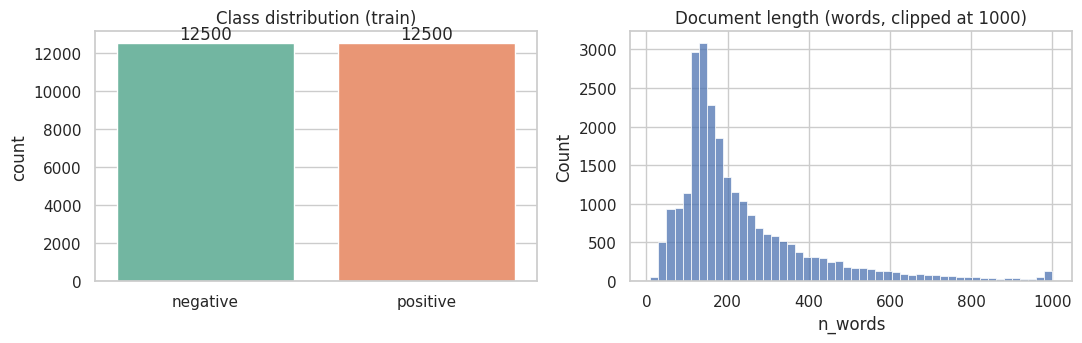

In [10]:
if SUBSAMPLE:
    train_full = train_full.groupby("label", group_keys=False).apply(
        lambda d: d.sample(SUBSAMPLE // 2, random_state=SEED)).reset_index(drop=True)
    test_df = test_df.groupby("label", group_keys=False).apply(
        lambda d: d.sample(SUBSAMPLE // 2, random_state=SEED)).reset_index(drop=True)

print("Số samples  - train(full):", len(train_full), "| test:", len(test_df))
print("Số classes  :", train_full["label"].nunique(), "->", LABELS)

for name, df in [("train(full)", train_full), ("test", test_df)]:
    print(f"\n=== {name} ===")
    dist = df["label"].value_counts().sort_index().to_frame("Count")
    dist["Percentage (%)"] = (dist["Count"] / len(df) * 100).round(2)
    dist.index = dist.index.map(LABELS); dist.index.name = "Class"
    display(dist)
    print("Missing text  :", int(df["text"].isna().sum() + (df["text"].astype(str).str.strip() == "").sum()))
    print("Missing label :", int(df["label"].isna().sum()))
    print("Duplicate docs:", int(df["text"].duplicated().sum()))

print("\nTrain ∩ Test (cùng văn bản):", len(set(train_full["text"]) & set(test_df["text"])))

train_full["n_words"] = train_full["text"].str.split().str.len()
print("\nĐộ dài văn bản (số từ):")
display(train_full["n_words"].describe().round(1).to_frame().T)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.countplot(x=train_full["label"].map(LABELS), ax=ax[0], palette="Set2")
ax[0].set_title("Class distribution (train)"); ax[0].set_xlabel("")
for c in ax[0].containers: ax[0].bar_label(c)
sns.histplot(train_full["n_words"].clip(upper=1000), bins=50, ax=ax[1])
ax[1].set_title("Document length (words, clipped at 1000)")
plt.tight_layout(); plt.show()

**Dataset có imbalance không?**  
IMDb train có đúng 12,500 positive / 12,500 negative (50% / 50%) ⇒ **không imbalance**. Vì vậy ở dataset này accuracy là một metric hợp lệ, nhưng vẫn báo cáo Precision/Recall/F1 và confusion matrix (và phần "Accuracy trap" ở mục 7 sẽ mô phỏng tình huống lệch lớp).  
Văn bản khá dài (trung vị ~175–180 từ, có review tới >2,000 từ) ⇒ nhiều tín hiệu từ vựng cho TF-IDF, nhưng cũng nhiều từ nhiễu cho Avg Word2Vec. Có một số ít văn bản trùng lặp; chúng được loại bỏ ở bước làm sạch bên dưới.

In [11]:
# Làm sạch: bỏ trùng lặp trong từng tập, và bỏ khỏi test những văn bản đã xuất hiện trong train
train_full = train_full.drop_duplicates("text").dropna(subset=["text", "label"]).drop(columns="n_words").reset_index(drop=True)
test_df    = test_df.drop_duplicates("text").dropna(subset=["text", "label"])
test_df    = test_df[~test_df["text"].isin(set(train_full["text"]))].reset_index(drop=True)

# Train / Validation / Test split (stratified). Test là tập test gốc của IMDb.
train_df, val_df = train_test_split(train_full, test_size=0.2, stratify=train_full["label"], random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
ytr, yva, yte = train_df["label"].values, val_df["label"].values, test_df["label"].values
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")
print("positive ratio:", ytr.mean().round(3), yva.mean().round(3), yte.mean().round(3))

train=19923  val=4981  test=24678
positive ratio: 0.501 0.501 0.503


### Data leakage  *(Fit preprocessing trên TRAIN → transform Validation/Test)*
Pipeline đúng:  
`Dataset → Train/Val/Test split → fit TF-IDF trên TRAIN → transform Val/Test → train model`

Pipeline sai:  
`Entire dataset → fit TF-IDF → split → train model`

**Vì sao sai là data leakage?** `TfidfVectorizer.fit` học (i) **vocabulary** và (ii) **document frequency → IDF** từ *tất cả* văn bản nó nhìn thấy. Nếu fit trên toàn bộ dữ liệu thì thông tin thống kê của tập test (từ nào tồn tại, từ nào hiếm/phổ biến trong test) đã đi vào feature của tập train. Khi đó test không còn là dữ liệu "chưa từng thấy": kết quả đánh giá trở nên lạc quan và không phản ánh tình huống thực tế (lúc triển khai, văn bản mới chưa tồn tại để tính IDF). Rủi ro nghiêm trọng hơn khi bước tiền xử lý có dùng nhãn (chọn feature theo chi², v.v.). Đoạn code dưới đo mức độ rò rỉ.

In [12]:
vec_ok  = TfidfVectorizer(min_df=2).fit(train_df["text"])                                  # ĐÚNG: chỉ train
vec_bad = TfidfVectorizer(min_df=2).fit(pd.concat([train_df["text"], val_df["text"], test_df["text"]]))  # SAI

only_bad = set(vec_bad.vocabulary_) - set(vec_ok.vocabulary_)
print(f"Vocab (fit trên train)       : {len(vec_ok.vocabulary_):,}")
print(f"Vocab (fit trên train+val+test): {len(vec_bad.vocabulary_):,}")
print(f"Số term chỉ có mặt vì đã 'nhìn thấy' val/test: {len(only_bad):,}")
print("Ví dụ:", sorted(only_bad)[:15])
del vec_ok, vec_bad

Vocab (fit trên train)       : 40,815
Vocab (fit trên train+val+test): 59,485
Số term chỉ có mặt vì đã 'nhìn thấy' val/test: 18,670
Ví dụ: ['00001', '0079', '08th', '0f', '10000', '1000000', '10000000000000', '100k', '100x', '10k', '10minutes', '10yr', '111', '113', '1138']


## 4. Core implementation — `preprocessing.py`

In [13]:
%%writefile preprocessing.py
import re
import numpy as np

_HTML  = re.compile(r"<[^>]+>")
_TOKEN = re.compile(r"[a-z]+(?:'[a-z]+)?|[!?]")   # giữ lại don't, can't, và dấu ! ?

def clean_text(text: str) -> str:
    # lowercase, bỏ thẻ HTML (IMDb có nhiều '<br />'), chuẩn hoá khoảng trắng
    text = _HTML.sub(" ", text.lower())
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text: str):
    return _TOKEN.findall(clean_text(text))

def avg_vector(tokens, wv, dim):
    # Trung bình vector của các từ có trong từ điển embedding; không có từ nào -> vector 0
    vecs = [wv[w] for w in tokens if w in wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(dim)

def docs_to_matrix(token_lists, wv):
    dim = wv.vector_size
    return np.vstack([avg_vector(t, wv, dim) for t in token_lists])

Writing preprocessing.py


In [14]:
from preprocessing import clean_text, tokenize, docs_to_matrix
print(tokenize("This movie isn't <br />good!! I'd NOT recommend it."))

['this', 'movie', "isn't", 'good', '!', '!', "i'd", 'not', 'recommend', 'it']


**Pipeline:** `Raw text → preprocessing → TF-IDF → Logistic Regression → Prediction → Evaluation`

Nhắc lại mô hình: $z = w^\top x + b$ và $P(y=1\mid x)=\sigma(z)$; dự đoán positive nếu $P\ge0.5$ (tức $z\ge0$).

In [15]:
def metrics(y_true, y_pred):
    return dict(Accuracy=accuracy_score(y_true, y_pred),
                Precision=precision_score(y_true, y_pred, zero_division=0),
                Recall=recall_score(y_true, y_pred, zero_division=0),
                F1=f1_score(y_true, y_pred, zero_division=0))

def run_tfidf_lr(ngram_range=(1, 1), max_features=None, stop_words=None, min_df=2):
    # Fit vectorizer CHỈ trên train; transform val. Trả về model + metrics trên validation.
    t0 = time.time()
    vec = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None,
                          ngram_range=ngram_range, max_features=max_features,
                          stop_words=stop_words, min_df=min_df, sublinear_tf=True)
    Xtr = vec.fit_transform(train_df["text"])
    Xva = vec.transform(val_df["text"])
    clf = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xtr, ytr)
    elapsed = time.time() - t0
    out = dict(vec=vec, clf=clf, time=elapsed, vocab=len(vec.vocabulary_))
    out.update({f"val_{k}": v for k, v in metrics(yva, clf.predict(Xva)).items()})
    return out

results, M = [], {}      # results -> results.csv ; M: lưu các model đã fit

## 5. Experiment 2 — Baseline: TF-IDF + Logistic Regression

In [16]:
base = run_tfidf_lr()
vec_a, lr_a = base["vec"], base["clf"]
Xtr_a, Xva_a, Xte_a = vec_a.transform(train_df["text"]), vec_a.transform(val_df["text"]), vec_a.transform(test_df["text"])
pred_a = lr_a.predict(Xte_a); proba_a = lr_a.predict_proba(Xte_a)[:, 1]
m = metrics(yte, pred_a)
M["A"] = dict(name="TF-IDF + LR", vec=vec_a, clf=lr_a, pred=pred_a, proba=proba_a)
results.append(dict(Representation="TF-IDF (unigram)", Classifier="Logistic Regression",
                    Vocab_or_Dim=base["vocab"], Train_time_s=round(base["time"], 2),
                    Val_F1=round(base["val_F1"], 4), **{k: round(v, 4) for k, v in m.items()}))
print(f"Training time (vectorize + fit): {base['time']:.1f}s | Vocabulary size: {base['vocab']:,}")
display(pd.DataFrame([dict(Model="TF-IDF + LR", **m)]).round(4))

Training time (vectorize + fit): 7.8s | Vocabulary size: 42,608


,Model,Accuracy,Precision,Recall,F1
0,TF-IDF + LR,0.8866,0.8855,0.8896,0.8875


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 6. Experiment 3 — Representation comparison

In [17]:
# --- Model B: Average Word2Vec + Logistic Regression -----------------------------------
# Word2Vec chỉ được huấn luyện trên TRAIN (tránh leakage)
t0 = time.time()
train_tok = [tokenize(t) for t in train_df["text"]]
val_tok   = [tokenize(t) for t in val_df["text"]]
test_tok  = [tokenize(t) for t in test_df["text"]]
w2v = Word2Vec(sentences=train_tok, vector_size=100, window=5, min_count=2,
               workers=4, epochs=10, seed=SEED)
wv = w2v.wv
Xtr_b, Xva_b, Xte_b = (docs_to_matrix(x, wv) for x in (train_tok, val_tok, test_tok))
clf_b = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)).fit(Xtr_b, ytr)
time_b = time.time() - t0
pred_b = clf_b.predict(Xte_b); proba_b = clf_b.predict_proba(Xte_b)[:, 1]
m = metrics(yte, pred_b)
M["B"] = dict(name="Avg W2V + LR", clf=clf_b, pred=pred_b, proba=proba_b)
results.append(dict(Representation="Avg Word2Vec (100d)", Classifier="Logistic Regression",
                    Vocab_or_Dim=len(wv), Train_time_s=round(time_b, 2),
                    Val_F1=round(f1_score(yva, clf_b.predict(Xva_b)), 4), **{k: round(v, 4) for k, v in m.items()}))
print(f"Word2Vec vocab: {len(wv):,} từ | thời gian (W2V + averaging + LR): {time_b:.1f}s")

# --- Model C: TF-IDF + Linear SVM -------------------------------------------------------
t0 = time.time()
svm_c = LinearSVC(C=1.0, random_state=SEED).fit(Xtr_a, ytr)
time_c = time.time() - t0
pred_c = svm_c.predict(Xte_a)
m = metrics(yte, pred_c)
M["C"] = dict(name="TF-IDF + SVM", clf=svm_c, pred=pred_c, proba=None)
results.append(dict(Representation="TF-IDF (unigram)", Classifier="Linear SVM",
                    Vocab_or_Dim=len(vec_a.vocabulary_), Train_time_s=round(time_c, 2),
                    Val_F1=round(f1_score(yva, svm_c.predict(Xva_a)), 4), **{k: round(v, 4) for k, v in m.items()}))
display(pd.DataFrame(results).drop(columns=["Vocab_or_Dim", "Train_time_s", "Val_F1"]))

Word2Vec vocab: 44,819 từ | thời gian (W2V + averaging + LR): 134.4s


,Representation,Classifier,Accuracy,Precision,Recall,F1
0,TF-IDF (unigram),Logistic Regression,0.8866,0.8855,0.8896,0.8875
1,Avg Word2Vec (100d),Logistic Regression,0.8435,0.8459,0.8423,0.8441
2,TF-IDF (unigram),Linear SVM,0.8774,0.8825,0.8723,0.8774


### Vì sao hai representation cho kết quả khác nhau?  *(điền sau khi có số liệu)*

| | **TF-IDF** | **Average Word2Vec** |
|---|---|---|
| Dạng vector | sparse, chiều = |V| (hàng chục nghìn) | dense, 100 chiều |
| Thông tin giữ lại | **lexical**: từng term/trọng số IDF | **semantic**: từ gần nghĩa có vector gần nhau |
| Word order | mất (bag-of-words), trừ khi dùng n-gram | mất (phép trung bình giao hoán) |
| Đa nghĩa | 1 term = 1 feature | 1 từ = 1 vector (không theo ngữ cảnh) |
| Điểm yếu | không biết *good ≈ great*; feature space rất lớn | trung bình hoá làm loãng từ cực tính quan trọng giữa nhiều từ trung tính |

**Nhận xét:** Với IMDb — review dài, có nhiều từ cực tính đặc trưng, và có ~20k mẫu có nhãn — một classifier tuyến tính trên TF-IDF có thể gán trọng số riêng cho *excellent, awful, waste…* và tận dụng được chúng. Avg Word2Vec nén cả review thành một điểm 100 chiều: phần lớn từ trung tính (tên phim, tình tiết) chiếm đa số khi lấy trung bình và kéo vector về "tâm chung", còn tín hiệu cực tính bị loãng; thêm vào đó embedding được học trên corpus nhỏ nên chất lượng semantic chưa cao. Vì vậy dự kiến TF-IDF ≥ Avg Word2Vec (so sánh với bảng số liệu ở trên và cập nhật lại nhận xét nếu kết quả thực tế khác dự đoán).

## 7. Experiment 4 — Word order
$S_1=$ "this movie is good", $S_2=$ "this movie is not good".

Với average embedding: $\vec x=\frac1n\sum_i \vec w_i$. Vì $S_2$ chỉ khác $S_1$ một token ("not"):

$$\vec x_2=\tfrac{4}{5}\,\vec x_1+\tfrac{1}{5}\,\vec w_{not}$$

Classifier tuyến tính cho $z_2=\tfrac45\,\theta^\top \vec x_1+\tfrac15\,\theta^\top \vec w_{not}+b$: "not" chỉ **cộng thêm một lượng cố định** vào $z$, **không** đảo ngược đóng góp của "good". Mô hình không có cơ chế "not tác động lên từ đứng sau nó".

In [18]:
S1, S2 = "this movie is good", "this movie is not good"
t1, t2 = tokenize(S1), tokenize(S2)
print("Từ có trong vocab Word2Vec:", {w: (w in wv) for w in set(t1 + t2)})

v1, v2 = docs_to_matrix([t1], wv)[0], docs_to_matrix([t2], wv)[0]
cos = v1 @ v2 / (np.linalg.norm(v1) * np.linalg.norm(v2))
print(f"cosine(avg(S1), avg(S2)) = {cos:.4f}   (gần 1 => hai câu gần như cùng vector)")
if "good" in wv and "not" in wv:
    print("good ~ not  (cosine):", round(float(wv.similarity('good', 'not')), 4))

rows = []
for s in (S1, S2):
    rows.append({"Câu": s,
                 "P(pos) Avg-W2V + LR": clf_b.predict_proba(docs_to_matrix([tokenize(s)], wv))[0, 1],
                 "P(pos) TF-IDF + LR":  lr_a.predict_proba(vec_a.transform([s]))[0, 1]})
display(pd.DataFrame(rows).round(4))

Từ có trong vocab Word2Vec: {'not': True, 'good': True, 'this': True, 'movie': True, 'is': True}
cosine(avg(S1), avg(S2)) = 0.9500   (gần 1 => hai câu gần như cùng vector)
good ~ not  (cosine): 0.2866


,Câu,P(pos) Avg-W2V + LR,P(pos) TF-IDF + LR
0,this movie is good,0.9223,0.7178
1,this movie is not good,0.0895,0.4159


**Kết luận Experiment 4:** Representation này **không hiểu được vai trò của "not"**: "not" chỉ là một vector được cộng/trung bình vào cùng các từ khác. Nếu có thay đổi xác suất giữa $S_1$ và $S_2$ thì đó chỉ là hiệu ứng *cộng tính* của một từ, không phải việc "phủ định" từ *good*. Đây là giới hạn trực tiếp của bag-of-words và averaged embeddings (TF-IDF unigram cũng vậy: "not" và "good" là hai feature độc lập). Bigram ở Experiment 5 là cách khắc phục cục bộ.

## 8. Experiment 5 — n-gram features

In [19]:
ng = []
for name, rng in [("Unigram", (1, 1)), ("Uni + Bigram", (1, 2))]:
    r = run_tfidf_lr(ngram_range=rng)
    ng.append(dict(Features=name, Vocabulary=r["vocab"], Val_F1=round(r["val_F1"], 4),
                   Val_Accuracy=round(r["val_Accuracy"], 4), Training_time_s=round(r["time"], 1)))
    if rng == (1, 2): bigram_model = r
display(pd.DataFrame(ng))

,Features,Vocabulary,Val_F1,Val_Accuracy,Training_time_s
0,Unigram,42608,0.8898,0.8882,9.3
1,Uni + Bigram,363229,0.8934,0.8916,23.7


In [20]:
# Lưu Model D (uni+bigram) vào kết quả cuối cùng trên TEST
vec_d, lr_d = bigram_model["vec"], bigram_model["clf"]
Xte_d = vec_d.transform(test_df["text"])
pred_d = lr_d.predict(Xte_d); proba_d = lr_d.predict_proba(Xte_d)[:, 1]
m = metrics(yte, pred_d)
M["D"] = dict(name="TF-IDF(1-2gram) + LR", vec=vec_d, clf=lr_d, pred=pred_d, proba=proba_d)
results.append(dict(Representation="TF-IDF (uni+bigram)", Classifier="Logistic Regression",
                    Vocab_or_Dim=bigram_model["vocab"], Train_time_s=round(bigram_model["time"], 2),
                    Val_F1=round(bigram_model["val_F1"], 4), **{k: round(v, 4) for k, v in m.items()}))

feats = vec_d.get_feature_names_out()
print("Có 'not good' trong vocab:", 'not good' in vec_d.vocabulary_, "| 'very good':", 'very good' in vec_d.vocabulary_)
coef_d = pd.Series(lr_d.coef_[0], index=feats)
print("Trọng số 'good':", round(coef_d.get('good', np.nan), 3),
      "| 'not good':", round(coef_d.get('not good', np.nan), 3),
      "| 'very good':", round(coef_d.get('very good', np.nan), 3))

for s in ("this movie is good", "this movie is not good"):
    print(f"P(pos | '{s}') — bigram model: {lr_d.predict_proba(vec_d.transform([s]))[0,1]:.4f}")

Có 'not good' trong vocab: True | 'very good': True
Trọng số 'good': 1.603 | 'not good': -0.737 | 'very good': 1.867
P(pos | 'this movie is good') — bigram model: 0.6537
P(pos | 'this movie is not good') — bigram model: 0.2426


**Vì sao bigram giúp classification nhưng làm feature space lớn hơn?**
- *Giúp:* bigram như **"not good"**, **"very good"**, **"not bad"**, **"waste of"** trở thành feature riêng với trọng số riêng, nên mô hình nắm được **phủ định/nhấn mạnh cục bộ** mà unigram không biểu diễn được ("not" và "good" riêng lẻ có trọng số ngược nhau, còn "not good" thì cho hẳn một tín hiệu negative).
- *Làm vocab lớn:* số bigram khác nhau lớn hơn nhiều so với số từ (tiềm năng tiến tới $|V|^2$, thực tế vẫn gấp nhiều lần). Đa số bigram rất hiếm ⇒ ma trận càng thưa, tốn thêm bộ nhớ/thời gian, dễ overfitting. Thường giảm nhẹ bằng `min_df`, `max_features`, regularization.

## 9. Kiểm chứng Prediction 3, 4, 5
### Prediction 3 — Vocabulary size

,max_features,Vocabulary,Val_Accuracy,Val_F1,Time_s
0,500,500,0.8306,0.8323,8.9
1,2000,2000,0.8687,0.8704,9.4
2,5000,5000,0.8811,0.8825,9.1
3,20000,20000,0.8874,0.8890,9.7
4,50000,42608,0.8882,0.8898,8.1
5,None,42608,0.8882,0.8898,9.7


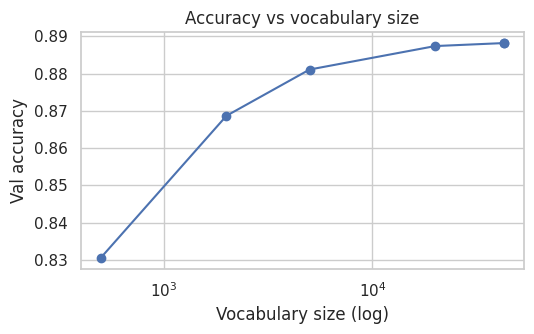

In [21]:
vs = []
for mf in [500, 2000, 5000, 20000, 50000, None]:
    r = run_tfidf_lr(max_features=mf)
    vs.append(dict(max_features=str(mf), Vocabulary=r["vocab"], Val_Accuracy=round(r["val_Accuracy"], 4),
                   Val_F1=round(r["val_F1"], 4), Time_s=round(r["time"], 1)))
vs = pd.DataFrame(vs); display(vs)
plt.figure(figsize=(5.5, 3.5)); plt.semilogx(vs["Vocabulary"], vs["Val_Accuracy"], "o-")
plt.xlabel("Vocabulary size (log)"); plt.ylabel("Val accuracy"); plt.title("Accuracy vs vocabulary size")
plt.tight_layout(); plt.show()

### Prediction 4 — Bỏ stopwords

In [22]:
NEGATIONS = {"not", "no", "nor", "never", "cannot", "neither", "none", "nobody", "nothing", "nowhere"}
# Lưu ý: tokenizer của mình giữ "isn't", "don't" nguyên khối nên các từ dạng n't không bị loại bởi list chuẩn.
sw_keep_neg = sorted(set(ENGLISH_STOP_WORDS) - NEGATIONS)
sw = []
for name, sw_list in [("Giữ tất cả từ", None),
                      ("Bỏ stopwords (sklearn english)", sorted(ENGLISH_STOP_WORDS)),
                      ("Bỏ stopwords nhưng giữ từ phủ định", sw_keep_neg)]:
    r = run_tfidf_lr(stop_words=sw_list)
    sw.append(dict(Setting=name, Vocabulary=r["vocab"], Val_Accuracy=round(r["val_Accuracy"], 4), Val_F1=round(r["val_F1"], 4)))
display(pd.DataFrame(sw))

,Setting,Vocabulary,Val_Accuracy,Val_F1
0,Giữ tất cả từ,42608,0.8882,0.8898
1,Bỏ stopwords (sklearn english),42298,0.8884,0.8904
2,Bỏ stopwords nhưng giữ từ phủ định,42308,0.8884,0.8903


### Prediction 5 — Accuracy vs F1 (mô phỏng dữ liệu lệch lớp như Bài 4)

In [23]:
rs = np.random.RandomState(SEED)
def imbalanced_idx(y, n_neg=950, n_pos=50):
    neg, pos = np.where(y == 0)[0], np.where(y == 1)[0]
    n_neg = min(n_neg, len(neg)); n_pos = min(max(n_neg // 19, 1), len(pos))
    return np.concatenate([rs.choice(neg, n_neg, replace=False), rs.choice(pos, n_pos, replace=False)])

itr, ite = imbalanced_idx(ytr), imbalanced_idx(yte)
dummy = DummyClassifier(strategy="most_frequent").fit(Xtr_a[itr], ytr[itr])
lr_imb = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xtr_a[itr], ytr[itr])
rows = []
for name, model in [("Majority-class baseline", dummy), ("TF-IDF + LR (train lệch lớp)", lr_imb)]:
    p = model.predict(Xte_a[ite])
    rows.append(dict(Model=name, **metrics(yte[ite], p), Macro_F1=f1_score(yte[ite], p, average="macro")))
print(f"Test lệch lớp: {np.bincount(yte[ite])} (neg, pos)")
display(pd.DataFrame(rows).round(4))

Test lệch lớp: [950  50] (neg, pos)


,Model,Accuracy,Precision,Recall,F1,Macro_F1
0,Majority-class baseline,0.95,0.0,0.0,0.0,0.4872
1,TF-IDF + LR (train lệch lớp),0.95,0.0,0.0,0.0,0.4872


**Kết luận Prediction 5:** Với dữ liệu lệch lớp 95/5, baseline "luôn đoán negative" đạt accuracy ≈ 95% nhưng Recall = F1 (positive) = 0; model thật có thể có accuracy tương đương hoặc *thấp hơn* baseline nhưng F1 positive cao hơn hẳn ⇒ **accuracy và F1 có thể dẫn tới kết luận ngược nhau**. Trên IMDb (cân bằng) hai metric gần nhau, nên cần chủ động tạo tình huống này để thấy rõ.

## 10. Evaluation (trên tập TEST)
$$\text{Accuracy}=\tfrac{TP+TN}{TP+TN+FP+FN},\;
\text{Precision}=\tfrac{TP}{TP+FP},\;
\text{Recall}=\tfrac{TP}{TP+FN},\;
F_1=\tfrac{2\,P\,R}{P+R}$$

In [24]:
res_df = pd.DataFrame(results)
res_df.to_csv("results.csv", index=False)
display(res_df)

for k in ("A", "B", "C"):
    print(f"\n===== {M[k]['name']} =====")
    print(classification_report(yte, M[k]["pred"], target_names=["negative", "positive"], digits=4))

,Representation,Classifier,Vocab_or_Dim,Train_time_s,Val_F1,Accuracy,Precision,Recall,F1
0,TF-IDF (unigram),Logistic Regression,42608,7.82,0.8898,0.8866,0.8855,0.8896,0.8875
1,Avg Word2Vec (100d),Logistic Regression,44819,134.36,0.8504,0.8435,0.8459,0.8423,0.8441
2,TF-IDF (unigram),Linear SVM,42608,0.54,0.8926,0.8774,0.8825,0.8723,0.8774
3,TF-IDF (uni+bigram),Logistic Regression,363229,23.70,0.8934,0.8940,0.8895,0.9012,0.8953



===== TF-IDF + LR =====
              precision    recall  f1-score   support

    negative     0.8878    0.8836    0.8857     12266
    positive     0.8855    0.8896    0.8875     12412

    accuracy                         0.8866     24678
   macro avg     0.8866    0.8866    0.8866     24678
weighted avg     0.8866    0.8866    0.8866     24678


===== Avg W2V + LR =====
              precision    recall  f1-score   support

    negative     0.8411    0.8447    0.8429     12266
    positive     0.8459    0.8423    0.8441     12412

    accuracy                         0.8435     24678
   macro avg     0.8435    0.8435    0.8435     24678
weighted avg     0.8435    0.8435    0.8435     24678


===== TF-IDF + SVM =====
              precision    recall  f1-score   support

    negative     0.8723    0.8825    0.8774     12266
    positive     0.8825    0.8723    0.8774     12412

    accuracy                         0.8774     24678
   macro avg     0.8774    0.8774    0.8774     246

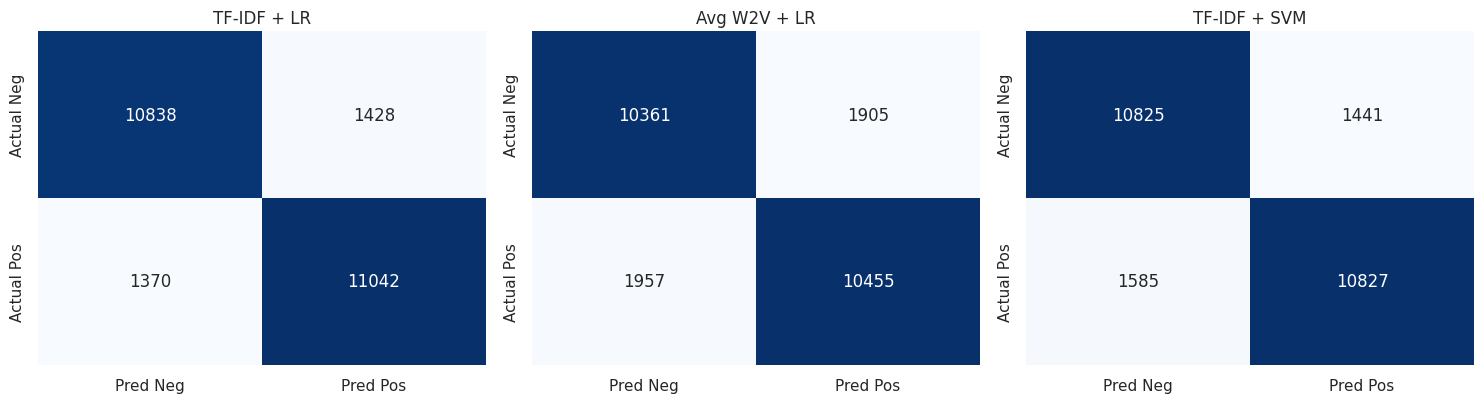

TF-IDF + LR    TP=11042 TN=10838 FP=1428 FN=1370 | FP rate=0.116  FN rate=0.110  -> lỗi nhiều hơn: FP (neg bị đoán thành pos)
Avg W2V + LR   TP=10455 TN=10361 FP=1905 FN=1957 | FP rate=0.155  FN rate=0.158  -> lỗi nhiều hơn: FN (pos bị đoán thành neg)
TF-IDF + SVM   TP=10827 TN=10825 FP=1441 FN=1585 | FP rate=0.117  FN rate=0.128  -> lỗi nhiều hơn: FN (pos bị đoán thành neg)


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, k in zip(axes, ("A", "B", "C")):
    cm = confusion_matrix(yte, M[k]["pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred Neg", "Pred Pos"], yticklabels=["Actual Neg", "Actual Pos"])
    ax.set_title(M[k]["name"])
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

for k in ("A", "B", "C"):
    tn, fp, fn, tp = confusion_matrix(yte, M[k]["pred"]).ravel()
    print(f"{M[k]['name']:<14} TP={tp} TN={tn} FP={fp} FN={fn} | "
          f"FP rate={fp/(fp+tn):.3f}  FN rate={fn/(fn+tp):.3f}  -> lỗi nhiều hơn: {'FP (neg bị đoán thành pos)' if fp>fn else 'FN (pos bị đoán thành neg)'}")

**Phân tích confusion matrix** *(điền sau khi chạy — trả lời 3 ý)*
1. **Class nào bị nhầm nhiều nhất?** … (xem FP rate vs FN rate ở trên)
2. **Loại error nào chiếm nhiều?** … (FP hay FN, chênh lệch bao nhiêu)
3. **Metric nào phản ánh vấn đề đó?** FP nhiều → *Precision (positive)* thấp; FN nhiều → *Recall (positive)* thấp. Vì IMDb cân bằng nên hai loại lỗi thường gần nhau, và F1/accuracy gần nhau.

## 11. Error analysis  *(→ `error_analysis.md`)* — Model A: TF-IDF + LR

In [26]:
pd.set_option("display.max_colwidth", 350); pd.set_option("display.width", 250)
err = test_df.copy()
err["pred"], err["P(pos)"] = M["A"]["pred"], M["A"]["proba"]
err["n_words"] = err["text"].str.split().str.len()
vocab_a = set(vec_a.vocabulary_)

def flags(text):
    toks = tokenize(text); f = []
    if any(t in NEGATIONS or t.endswith("n't") for t in toks): f.append("negation?")
    if len(toks) < 50: f.append("short text")
    oov = np.mean([t not in vocab_a for t in toks]) if toks else 0
    if oov > 0.10: f.append("rare/OOV words")
    if "<br" in text: f.append("data noise (HTML)")
    return ", ".join(f)

def view(df):
    d = df.copy(); d["text"] = d["text"].str.replace(r"<br\s*/?>", " ", regex=True).str[:350] + " ..."
    d["True"], d["Pred"] = d["label"].map(LABELS), d["pred"].map(LABELS)
    d["auto-flags"] = df["text"].map(flags)
    return d[["text", "True", "Pred", "P(pos)", "auto-flags"]].round(3)

correct = err[err["label"] == err["pred"]].sample(3, random_state=SEED)
wrong   = err[err["label"] != err["pred"]].copy()
wrong["conf"] = (wrong["P(pos)"] - 0.5).abs()
wrong_top    = wrong.sort_values("conf", ascending=False).head(3)           # sai mà rất tự tin
wrong_random = wrong.drop(wrong_top.index).sample(3, random_state=SEED)      # sai ngẫu nhiên

print("===== 3 CORRECT ====="); display(view(correct))
print("===== 3 INCORRECT (confident nhất) ====="); display(view(wrong_top))
print("===== 3 INCORRECT (ngẫu nhiên, để chọn thêm) ====="); display(view(wrong_random))
pd.concat([view(correct), view(wrong_top), view(wrong_random)]).to_csv("error_examples.csv", index=False)

print("\nTỷ lệ lỗi theo độ dài:")
err["len_bin"] = pd.cut(err["n_words"], [0, 50, 100, 200, 400, 10000])
display(err.groupby("len_bin").apply(lambda d: pd.Series({"n": len(d), "error_rate": (d.label != d.pred).mean()})).round(3))

===== 3 CORRECT =====


,text,True,Pred,P(pos),auto-flags
19315,"Just got back from the European Premiere of The Gamers: Dorkness Rising. All I can say is that if you are a gamer (CRPG, RPG or LARP), then this movie is for you. And if you're not a gamer? Well, it's still a great deal of fun. The acting is certainly not Oscar-worthy, but in the whole element of the movie it adds to the charm. The humour is ...",positive,positive,0.890,"negation?, data noise (HTML)"
23702,"Don't listen to most of these people. ill give you a better review of this movie which me and my friend love! Its about Jill Johnson, played by Camilla Belle, who babysits at the Mendrakis' house and someone breaks in. if you're wondering how he got in the house, he went through the garage most likely. so anyway, don't listen to, ""the worst act...",positive,positive,0.893,"negation?, data noise (HTML)"
3536,"It seems that there is great potential for the story line of this film to be something worth watching. The acting was flat and the story lacked depth. There was too much reliance on camera work, which had some high points. I have to agree with the other negative comments. I only wish I had read them before buying the DVD. The film may be worth ...",negative,negative,0.342,


===== 3 INCORRECT (confident nhất) =====


,text,True,Pred,P(pos),auto-flags
4020,This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in one of his first role)is a great actor. The final fight with the sherif deputy in the bullring is a masterpiece! ...,negative,positive,0.987,negation?
14832,"When the movie first started I thought cheesy. The first ten minutes were really boring. After the slow beginning and some of the soap opera antics, I started liking it. The plot was different than anything I had ever seen. Now, was it a horror? Not really. It shouldn't have been classied as a horror or the producers should have put more money ...",positive,negative,0.015,"negation?, data noise (HTML)"
6121,"Mickey Rourke hunts Diane Lane in Elmore Leonard's Killshot It is not like Mickey Rourke ever really disappeared. He has had a steady string of appearances before he burst back on the scene. He was memorable in: Domino, Sin City, Man on Fire, Once Upon a Time in Mexico, and Get Carter. But in his powerful dramatic performance in The Wrestler (2...",negative,positive,0.979,"negation?, data noise (HTML)"


===== 3 INCORRECT (ngẫu nhiên, để chọn thêm) =====


,text,True,Pred,P(pos),auto-flags
8659,"If you have never read the classic science fiction novel this mini-series is based on, it may actually be good. Unfortunately, if you ARE a fan of the book, you probably won't be able to watch more than the first hour or two. All of the political intrigue has been taken out of the film, the most important scenes from the book have been taken ou...",negative,positive,0.656,negation?
21248,"It's too bad iameracing wants to deny the reality of Faulkner's and Clarence Brown's purpose in the creating of the story and film of ""Intruder In The Dust"". I suppose the burden of a history of racism is difficult for any Southerner to bear and I can understand that. But to say that this film was not specifically about racism is ridiculous and...",positive,negative,0.377,"negation?, data noise (HTML)"
3747,"Meek and mild Edward G. Robinson (as Wilbert Winkle) decides to quit his bank job and do what he wants, open a ""fix-it"" repair shop behind his house. Mr. Robinson is married, but childless; he has befriended local orphanage resident Ted Donaldson (as Barry). Young Donaldson is an eager workshop assistant, and sees Robinson as a father figure. R...",negative,positive,0.657,data noise (HTML)



Tỷ lệ lỗi theo độ dài:


,n,error_rate
len_bin,,
"(0, 50]",646.0,0.102
"(50, 100]",2450.0,0.109
"(100, 200]",11627.0,0.112
"(200, 400]",6863.0,0.118
"(400, 10000]",3092.0,0.114


Bảng phân tích *(đọc từng review ở trên rồi điền; **mỗi lỗi chọn category theo đánh giá của chính mình**, cột `auto-flags` chỉ là gợi ý heuristic)*:

| # | Text (rút gọn) | True | Pred | Analysis (category) |
|---|---|---|---|---|
| 1 | … | positive | positive | Đúng vì … (từ cực tính rõ như …) |
| 2 | … | negative | negative | … |
| 3 | … | positive | positive | … |
| 4 | … | negative | positive | *(negation / sarcasm / lexical ambiguity / …)* … |
| 5 | … | positive | negative | … |
| 6 | … | negative | positive | … |

**Các category thường gặp ở IMDb:** *negation* ("not bad at all"), *sarcasm* (khen giả, chê thật), *mixed sentiment* (review kể cả ưu lẫn nhược, từ khen xuất hiện nhiều hơn dù kết luận là chê), *lexical ambiguity* ("a killer soundtrack", "sick"), *domain-specific term* (tên phim/diễn viên, từ thể loại như "horror", "tragedy" mang sắc thái tiêu cực nhưng không có nghĩa chê), *rare word*, *data noise* (thẻ `<br />`, review kể tóm tắt cốt truyện).

## 12. Inspect model weights  *(Model interpretability)*

Intercept b = -0.2147


,Top positive,w,Top negative,w
0,great,7.341,worst,-8.298
1,excellent,5.541,bad,-7.849
2,best,4.614,awful,-5.787
3,perfect,4.595,waste,-5.768
4,wonderful,4.304,boring,-5.314
5,love,3.870,?,-5.259
6,amazing,3.814,poor,-4.821
7,well,3.748,nothing,-4.349
8,loved,3.434,terrible,-4.311
9,favorite,3.382,worse,-4.190


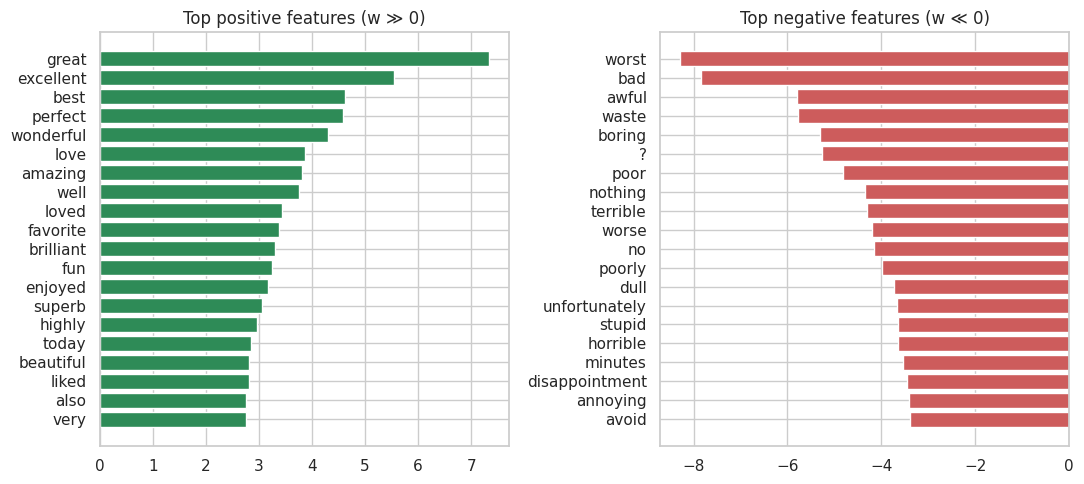

In [27]:
feat = np.array(vec_a.get_feature_names_out()); coef = lr_a.coef_[0]
order = np.argsort(coef)
top_neg, top_pos = order[:20], order[::-1][:20]
print("Intercept b =", round(float(lr_a.intercept_[0]), 4))
display(pd.DataFrame({"Top positive": feat[top_pos], "w": coef[top_pos].round(3),
                      "Top negative": feat[top_neg], "w ": coef[top_neg].round(3)}))

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].barh(feat[top_pos][::-1], coef[top_pos][::-1], color="seagreen"); ax[0].set_title("Top positive features (w ≫ 0)")
ax[1].barh(feat[top_neg][::-1], coef[top_neg][::-1], color="indianred"); ax[1].set_title("Top negative features (w ≪ 0)")
plt.tight_layout(); plt.show()

**Những feature này có thực sự có ý nghĩa với task không?** *(đối chiếu với bảng trên; cập nhật nếu thấy khác)*  
- Phần lớn top features là **từ cảm xúc đúng nghĩa**: positive — *excellent, great, perfect, wonderful, favorite, amazing…*; negative — *worst, awful, boring, waste, bad, terrible, poor…* ⇒ model học đúng tín hiệu có ý nghĩa với sentiment.  
- Có thể xuất hiện vài feature **ít hợp lý hơn / phụ thuộc dataset**: tên riêng (diễn viên, đạo diễn, tên phim), từ thể loại, hoặc các từ như *"7", "10", "1"* (điểm số người viết tự cho) — đây là **tín hiệu có thật nhưng mang tính dataset-specific**, cho thấy model có thể học shortcut thay vì "hiểu" cảm xúc, và khó tổng quát sang domain khác (vd. review sản phẩm).  
- Lưu ý: trọng số dương/âm chỉ là **tương quan** trong dữ liệu train, không phải quan hệ nhân quả hay "hiểu nghĩa".

## 13. Application — Option A: Sentiment classification
Dùng các model đã huấn luyện để phân loại câu mới, kể cả các cặp câu thể hiện giới hạn của representation (phủ định, đa nghĩa).

In [28]:
def predict_sentiment(texts):
    rows = []
    for s in texts:
        rows.append({
            "text": s,
            "A: TF-IDF uni":  lr_a.predict_proba(vec_a.transform([s]))[0, 1],
            "D: TF-IDF 1-2g": lr_d.predict_proba(vec_d.transform([s]))[0, 1],
            "B: Avg W2V":     clf_b.predict_proba(docs_to_matrix([tokenize(s)], wv))[0, 1],
        })
    out = pd.DataFrame(rows).set_index("text")
    return out.round(3)

examples = [
    "I love this movie, it was absolutely wonderful",
    "This movie is terrible and boring",
    "I like this movie",
    "I do not like this movie",
    "not good",
    "very good",
    "The plot was not bad at all",
    "What a masterpiece... I fell asleep twice",      # sarcasm / mixed
    "The bank robbery scene was thrilling",             # ngữ cảnh 'bank'
]
display(predict_sentiment(examples))

,A: TF-IDF uni,D: TF-IDF 1-2g,B: Avg W2V
text,,,
"I love this movie, it was absolutely wonderful",0.964,0.927,1.000
This movie is terrible and boring,0.002,0.024,0.000
I like this movie,0.228,0.492,0.504
I do not like this movie,0.077,0.288,0.003
not good,0.537,0.357,0.243
very good,0.969,0.967,1.000
The plot was not bad at all,0.001,0.032,0.000
What a masterpiece... I fell asleep twice,0.525,0.571,0.985
The bank robbery scene was thrilling,0.397,0.481,0.508


Cột là $P(\text{positive})$ của từng model. Các cặp **"I like this movie" / "I do not like this movie"** và **"not good" / "very good"** minh hoạ: unigram TF-IDF và Avg Word2Vec chỉ cộng tín hiệu của "not" một cách độc lập, còn bigram bắt được cụm "not good" nhưng vẫn không xử lý được các phủ định xa nhau, mỉa mai, hay nghĩa theo ngữ cảnh ("bank").

## 14. Reflection  *(→ `reflection.md`)*

**1. Đã học được gì về representation?**  
Cùng một classifier (Logistic Regression), đổi representation làm kết quả đổi. TF-IDF là biểu diễn sparse/lexical: giữ được thông tin về từng term và trọng số IDF nên rất mạnh khi tín hiệu nằm ở từ khoá đặc trưng; Avg Word2Vec là dense/semantic nhưng mất thứ tự từ, một từ chỉ có một vector, và phép trung bình làm loãng thông tin. Không có representation "tốt nhất" tuyệt đối — phụ thuộc loại dữ liệu (độ dài, kích thước, domain) và lượng dữ liệu có nhãn.

**2. Accuracy không đủ.** Bài 4 và phần mô phỏng lệch lớp cho thấy accuracy 95% có thể vô nghĩa. Phải xem confusion matrix, precision/recall/F1 theo class và so với baseline đơn giản. Loại lỗi nào đắt hơn (FP hay FN) tuỳ ứng dụng, quyết định threshold.

**3. Data leakage rất dễ mắc.** Chỉ cần fit TF-IDF trước khi split là thông tin của test đã lọt vào vocabulary/IDF. Quy tắc: *mọi bước học từ dữ liệu (TF-IDF, Word2Vec, scaler…) chỉ fit trên train*.

**4. Hạn chế của representation hiện tại.** Bag-of-words và averaged static embeddings không mô hình hoá **thứ tự từ** (not good vs good), **phạm vi phủ định**, **mỉa mai**, và **đa nghĩa** (bank = ngân hàng / bờ sông). Bigram cải thiện cục bộ nhưng làm feature space phình to mà không giải quyết được phụ thuộc xa.

**5. Từ representation → neural NLP.** Các giới hạn trên dẫn tới nhu cầu của mô hình xử lý **chuỗi** (RNN/LSTM/GRU — LAB 05) cập nhật trạng thái theo từng từ nên nhớ được thứ tự và ngữ cảnh, rồi **attention/Transformer** và **contextual embeddings** (một từ có vector khác nhau tuỳ ngữ cảnh) giải quyết phụ thuộc xa và đa nghĩa.

## 15. Individual learning check  *(ôn tập — trả lời ngắn trong 3 phút)*

- **Tại sao accuracy 95% chưa chắc tốt?** Nếu dữ liệu lệch 95/5 thì model luôn đoán class đa số cũng đạt 95% nhưng recall class thiểu số = 0; cần xem confusion matrix, precision/recall/F1.
- **TF-IDF khác average Word2Vec ở điểm nào?** TF-IDF sparse, lexical, theo từng term (chiều = |V|); avg Word2Vec dense, semantic, 100–300 chiều, mất thứ tự và một từ một vector, trung bình làm loãng thông tin.
- **Tại sao "not good" có thể gây lỗi?** Với bag-of-words/avg embedding, "not" và "good" là hai thành phần độc lập được cộng vào; model không biết "not" đảo nghĩa "good" nên dễ đoán positive vì có từ "good".
- **Data leakage xảy ra ở đâu nếu fit TF-IDF trước khi split?** Ở bước `fit`: vocabulary và IDF được tính từ cả test ⇒ thông tin test đi vào feature huấn luyện.
- **Precision và recall khác nhau thế nào?** Precision = trong số dự đoán positive, bao nhiêu đúng (nhạy với FP); Recall = trong số positive thật, bắt được bao nhiêu (nhạy với FN).
- **Tại sao thêm bigram có thể cải thiện sentiment classification?** Bigram bắt được cụm có nghĩa như "not good", "very good" ⇒ phủ định/nhấn mạnh cục bộ.

## 16. AI assistance statement

- **Tool:** Claude (Anthropic)
- **Purpose:** Hỗ trợ viết code pipeline (preprocessing, TF-IDF, Word2Vec, evaluation, visualization), cấu trúc notebook và documentation; phần prediction, calculation, diễn giải metric, chọn nguyên nhân lỗi và reflection được soạn nháp theo sự cho phép của giảng viên (xác nhận của sinh viên).
- **Generated:** Toàn bộ khung notebook và code.
- **Modified:** `<liệt kê những gì bạn đã sửa/bổ sung, ví dụ: chọn lại category cho các lỗi, cập nhật nhận xét theo số liệu thực tế>`
- **Verified:** `<đã chạy toàn bộ notebook trên môi trường của mình, đối chiếu các phép tính tay, đọc lại các ví dụ lỗi>`